In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Impostiamo lo stile dei grafici per renderli più professionali
plt.style.use('seaborn-v0_8-whitegrid')

# Definiamo i Ticker di Yahoo Finance
# HG=F (Copper Futures): Il rame è fondamentale per i lead frame e i collegamenti nei chip.
# GC=F (Gold Futures): L'oro è usato nel wire bonding per chip ad altissima affidabilità (es. automotive).
tickers = ['HG=F', 'GC=F']

# Estraiamo gli ultimi 5 anni di dati giornalieri
print("Scaricamento dei dati in corso...")
df_raw = yf.download(tickers, period="5y", interval="1d")

# Ci interessano solo i prezzi di chiusura corretti (Adj Close o Close)
prices = df_raw['Close'].copy()

# Rinominiamo le colonne per pulizia
prices.columns = ['Oro', 'Rame']

print(f"Dati estratti: {prices.shape[0]} giorni lavorativi.")
print(prices.tail()) # Mostra le ultime 5 righe


# Controlliamo i valori mancanti
print("Valori nulli prima della pulizia:\n", prices.isna().sum())

# Applichiamo il Forward Fill (riempie i NaN con l'ultimo valore valido precedente)
prices_clean = prices.ffill()

# Se il primo giorno in assoluto era un NaN, lo eliminiamo per sicurezza
prices_clean = prices_clean.dropna()
print("Valori nulli dopo la pulizia:\n", prices_clean.isna().sum())

/Users/certideal/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Scaricamento dei dati in corso...


[*********************100%***********************]  2 of 2 completed

Dati estratti: 1258 giorni lavorativi.
                    Oro    Rame
Date                           
2026-10-08  4157.000000  6.5190
2026-10-09  4216.299805  6.6425
2026-10-12  4190.600098  6.6985
2026-10-13  4177.299805  6.6780
2026-10-14  4112.500000  6.6755
Valori nulli prima della pulizia:
 Oro     0
Rame    0
dtype: int64
Valori nulli dopo la pulizia:
 Oro     0
Rame    0
dtype: int64


I log-return ci permettono di evitare gli under flow e di semplicemente sommare i rendimenti.
I modelli Arima e Monte Carlo simulation richideono che i dati seguano la Normale e i log che hanno supporto tra -inf e +inf si distribuiscono i modo più simmetrico.

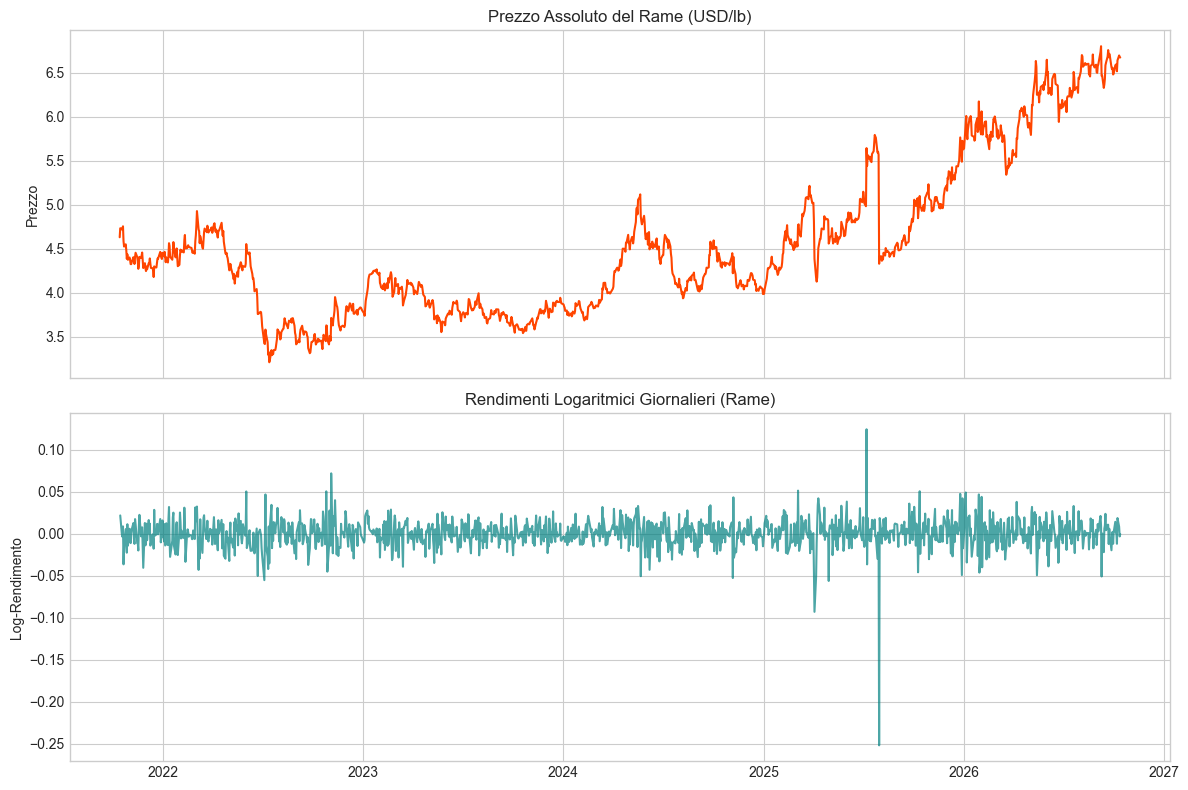

In [15]:
# calcolo dei rendimenti logaritmici giornalieri
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()

fig, axes = plt.subplots(2,1, figsize=(12, 8), sharex= True)
# Grafico dei prezzi del rame
axes[0].plot(prices_clean.index, prices_clean['Rame'], color= 'orangered')
axes[0].set_title('Prezzo Assoluto del Rame (USD/lb)')
axes[0].set_ylabel('Prezzo')
# Grafico dei rendimenti logaritmici (Rame)
axes[1].plot(log_returns.index, log_returns['Rame'], color='teal', alpha=0.7)
axes[1].set_title('Rendimenti Logaritmici Giornalieri (Rame)')
axes[1].set_ylabel('Log-Rendimento')

plt.tight_layout()
plt.show()

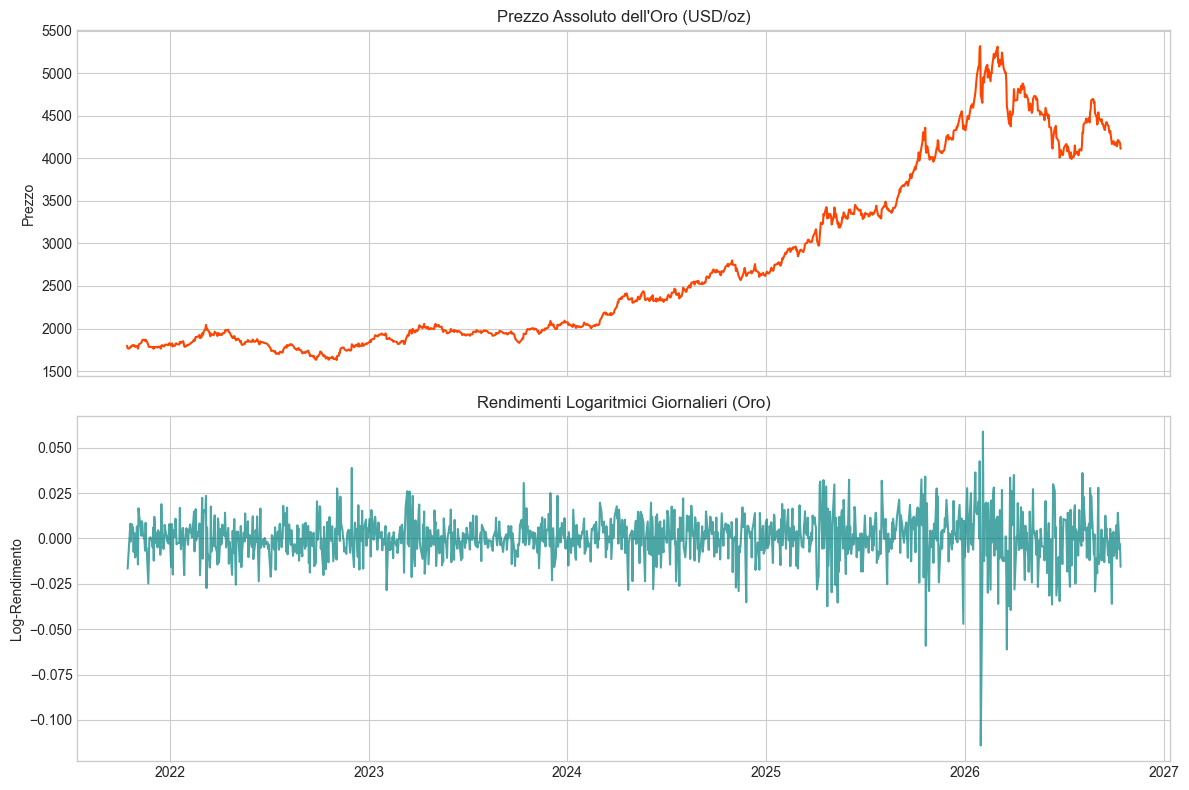

In [16]:
fig, axes = plt.subplots(2,1, figsize=(12, 8), sharex= True)
# Grafico dei prezzi dell'oro
axes[0].plot(prices_clean.index, prices_clean['Oro'], color= 'orangered')
axes[0].set_title('Prezzo Assoluto dell\'Oro (USD/oz)')
axes[0].set_ylabel('Prezzo')
# Grafico dei rendimenti logaritmici (Oro)
axes[1].plot(log_returns.index, log_returns['Oro'], color='teal', alpha=0.7)
axes[1].set_title('Rendimenti Logaritmici Giornalieri (Oro)')
axes[1].set_ylabel('Log-Rendimento')

plt.tight_layout()
plt.show()

## Cos'è la Stazionarietà e come funziona il test di Dickey-Fuller
Prima di prevedere il futuro, i modelli classici delle serie storiche (come ARIMA) richiedono che i dati siano stazionari.
Una serie temporale è stazionaria se le sue proprietà statistiche principali non cambiano nel tempo. Nello specifico:
Media costante: Il grafico non deve avere un trend evidente al rialzo o al ribasso.
Varianza costante: Le oscillazioni non devono allargarsi o stringersi sistematicamente col passare degli anni.

Se i prezzi del rame hanno un trend crescente (non stazionario), la media calcolata sui dati di 5 anni fa non è rappresentativa del prezzo di oggi. L'algoritmo andrebbe in confusione. Rendendo la serie stazionaria (usando i rendimenti logaritmici calcolati prima), stiamo dicendo al modello: "Non prevedere il prezzo assoluto che continua a salire, ma prevedi la Variazione di oggi rispetto a ieri", che oscilla sempre intorno allo zero.

## Come funziona il test Augmented Dickey-Fuller (ADF)?
Il test ADF è un test d'ipotesi statistico che cerca la presenza di una "radice unitaria" (una caratteristica matematica che rende la serie non stazionaria, come un trend stocastico).
Ipotesi Nulla (H 0): La serie temporale ha una radice unitaria (è NON stazionaria).
Ipotesi Alternativa (H1): La serie temporale non ha una radice unitaria (è stazionaria).

Cosa misura? Il test calcola un valore statistico (l'ADF Statistic) e lo converte in un p-value. Se il p-value è inferiore alla nostra soglia di confidenza (tipicamente 0.05, ovvero il 5%), rigettiamo l'ipotesi nulla e dichiariamo la serie stazionaria.

In [18]:
from statsmodels.tsa.stattools import adfuller

def esegui_test_adf(serie_temporale, nome_serie):
    """
    Funzione per eseguire il test di Dickey-Fuller e stampare i risultati in modo leggibile.
    """
    print(f"--- Test Augmented Dickey-Fuller per: {nome_serie} ---")
    
    # Eseguiamo il test
    # autolag='AIC' fa scegliere al test in automatico il numero ottimale di ritardi (lags)
    risultato = adfuller(serie_temporale.dropna(), autolag='AIC')
    
    adf_statistic = risultato[0]
    p_value = risultato[1]
    
    print(f"ADF Statistic: {adf_statistic:.4f}")
    print(f"p-value: {p_value:.4f}")
    
    # Valutazione dell'ipotesi
    if p_value < 0.05:
        print("Conclusione: p-value < 0.05. Rigettiamo l'Ipotesi Nulla (H0).")
        print("La serie temporale è STAZIONARIA. Pronta per il modello ARIMA.\n")
    else:
        print("Conclusione: p-value >= 0.05. NON possiamo rigettare l'Ipotesi Nulla (H0).")
        print("La serie temporale NON È STAZIONARIA (ha un trend). Non usare così in ARIMA!\n")

# 1. Testiamo i PREZZI ASSOLUTI del Rame (ci aspettiamo che NON sia stazionario)
esegui_test_adf(prices_clean['Rame'], "Prezzi Assoluti Rame")

# 2. Testiamo i RENDIMENTI LOGARITMICI del Rame calcolati nello step precedente
esegui_test_adf(log_returns['Rame'], "Rendimenti Logaritmici Rame")

--- Test Augmented Dickey-Fuller per: Prezzi Assoluti Rame ---
ADF Statistic: -0.6945
p-value: 0.8482
Conclusione: p-value >= 0.05. NON possiamo rigettare l'Ipotesi Nulla (H0).
La serie temporale NON È STAZIONARIA (ha un trend). Non usare così in ARIMA!

--- Test Augmented Dickey-Fuller per: Rendimenti Logaritmici Rame ---
ADF Statistic: -37.0815
p-value: 0.0000
Conclusione: p-value < 0.05. Rigettiamo l'Ipotesi Nulla (H0).
La serie temporale è STAZIONARIA. Pronta per il modello ARIMA.



In finanza, il prezzo di un asset ha due componenti fondamentali: il rendimento atteso (la direzione media verso cui sta andando) e la volatilità (l'incertezza o il rischio attorno a quella direzione).
Per questo motivo usiamo due modelli in sequenza: ARIMA modella la traiettoria media, mentre GARCH modella il rischio.
## ARIMA (AutoRegressive Integrated Moving Average)
A cosa serve: ARIMA serve a prevedere il valore futuro di una serie temporale basandosi esclusivamente sui suoi valori passati e sugli errori di previsione passati. Modella la "media" condizionata del processo.
Come funziona (I tre parametri p,d,q):
AR (p - AutoRegressivo): Assume che il valore di oggi dipenda dai valori dei giorni precedenti. Se il rame è salito per 3 giorni, l'inerzia potrebbe farlo salire anche oggi.
I (d - Integrato): Indica quante volte la serie deve essere "differenziata" per diventare stazionaria. Avendo noi già calcolato i rendimenti logaritmici (che sono stazionari, come provato dal test ADF), per noi d=0.
MA (q - Moving Average): Assume che il valore di oggi dipenda dagli "shock" o errori di previsione dei giorni passati.
L'Equazione Matematica (ARIMA per d=0):

$$ r_t = c + \sum_{i=1}^{p} \phi_i r_{t-i} + \sum_{j=1}^{q} \theta_j \epsilon_{t-j} + \epsilon_t $$
 
(Dove r 
t
​	
  è il rendimento al tempo t, c è una costante, ϕ e θ sono i pesi calcolati dal modello e ϵ 
t
​	
  è l'errore o rumore bianco).
  
Assunzioni critiche: ARIMA assume che le relazioni siano lineari e, cosa importantissima, che la varianza degli errori (ϵ 
t
​	
 ) sia costante nel tempo (Omoschedasticità).
## GARCH (Generalized Autoregressive Conditional Heteroskedasticity)
Il problema di ARIMA in finanza: Nei mercati finanziari, l'assunzione di varianza costante è falsa. Ci sono periodi di calma piatta e periodi di panico estremo (es. scoppio di una guerra, crisi dei semiconduttori). Questo fenomeno si chiama Volatility Clustering (a grappoli). Se usi solo ARIMA, sottostimi pesantemente il rischio durante le crisi.
A cosa serve: GARCH prende gli "errori" (i residui) lasciati da ARIMA e modella la loro varianza per prevedere quanto i prezzi oscilleranno domani.
L'Equazione Matematica (GARCH(1,1)):

$$ \sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2 $$

(La varianza di oggi $\sigma_t^2$ dipende da una costante di base $\omega$, dallo shock effettivo di ieri $\epsilon_{t-1}^2$, e dalla varianza che avevamo previsto per ieri $\sigma_{t-1}^2$).

Assunzioni: Assume che la volatilità sia "mean-reverting" (dopo un periodo di forte shock, il mercato tende sempre a tornare a una volatilità media di lungo periodo).

In [19]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)
import pmdarima as pm
from arch import arch_model

In [20]:
# 1. ADDESTRAMENTO ARIMA SUI RENDIMENTI DEL RAME
print("Ricerca del miglior modello ARIMA in corso...")

# Usiamo i rendimenti logaritmici calcolati nello step precedente (log_returns['Rame'])
# AutoARIMA cerca i parametri (p,d,q) migliori.
arima_model = pm.auto_arima(
    log_returns['Rame'],
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    d=0, # d=0 perché la serie log_returns è già stazionaria
    seasonal=False, # I dati finanziari giornalieri raramente hanno stagionalità fissa
    trace=True, # Mostra i tentativi a schermo
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)

print("\n--- Riassunto Modello ARIMA Ottimale ---")
print(arima_model.summary())

# 2. ESTRAZIONE DEI RESIDUI
# I residui sono ciò che ARIMA NON è riuscito a spiegare. 
# In finanza, questa è pura volatilità (rischio).
residui_arima = arima_model.resid()

# 3. ADDESTRAMENTO GARCH(1,1) SUI RESIDUI
print("\nAddestramento del modello GARCH per modellare la volatilità...")

# Inizializziamo un modello GARCH standard
# p=1 (ritardo degli shock passati), q=1 (ritardo della volatilità passata)
garch = arch_model(residui_arima, vol='Garch', p=1, q=1, rescale=False)

# Addestriamo il modello
garch_model = garch.fit(update_freq=5, disp='off')

print("\n--- Riassunto Modello GARCH ---")
print(garch_model.summary())

# 4. PREVISIONE (FORECAST) DEL PROSSIMO MESE (21 giorni lavorativi)
orizzonte_temporale = 21

# Prevediamo la media con ARIMA
arima_forecast = arima_model.predict(n_periods=orizzonte_temporale)

# Prevediamo la varianza (volatilità) con GARCH
garch_forecast = garch_model.forecast(horizon=orizzonte_temporale)
volatilita_prevista = np.sqrt(garch_forecast.variance.values[-1, :])

print(f"\nRendimento medio giornaliero previsto per domani: {arima_forecast.iloc[0]:.6f}")
print(f"Volatilità (deviazione standard) prevista per domani: {volatilita_prevista[0]:.6f}")

Ricerca del miglior modello ARIMA in corso...
Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-6574.436, Time=0.07 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=-6575.789, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-6576.358, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=-6576.432, Time=0.04 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=-6574.594, Time=0.04 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=-6573.017, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=-6574.805, Time=0.09 sec

Best model:  ARIMA(0,0,1)(0,0,0)[0]          
Total fit time: 0.315 seconds

--- Riassunto Modello ARIMA Ottimale ---
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1257
Model:               SARIMAX(0, 0, 1)   Log Likelihood                3290.216
Date:                Wed, 14 Oct 2026   AIC                          -6576.432
Time:  

La ricerca del modello: Le prime righe mostrano il programma che prova diverse combinazioni (es. ARIMA 1,0,1 poi 0,0,0, ecc.). Per ogni test calcola l'AIC, un punteggio che valuta la qualità del modello (più è basso/negativo, meglio è).

Il vincitore (Best model: ARIMA(0,0,1)): Il modello migliore per i dati sul rame è un ARIMA(0,0,1). Questo significa che i rendimenti passati non servono a prevedere quelli futuri (p=0), la serie è già stazionaria (d=0), ma l'errore o "shock" del giorno precedente ha un lieve impatto su oggi (q=1). In pratica, è un modello di media mobile (MA).

I Coefficienti (ma.L1 -0.0454): L'impatto dello shock di ieri sui rendimenti di oggi è leggermente negativo (-0.0454). Tuttavia, guardando la colonna P>|z| (0.070), questo valore è superiore a 0.05, indicando che la sua rilevanza statistica è debole.

I Test Diagnostici (Ljung-Box e Jarque-Bera):
Ljung-Box Prob (0.98): Ottima notizia. Essendo vicino a 1, significa che nei residui non ci sono pattern nascosti; il modello ha catturato tutto quello che poteva.
Jarque-Bera Prob (0.00): Indica che i tuoi dati non hanno una distribuzione "a campana" (normale). È tipico in finanza: significa che ci sono picchi estremi (code grasse / fat tails). È il motivo esatto per cui si usa il modello GARCH dopo l'ARIMA.

La Previsione Finale: Il tuo script prevede per il giorno di borsa successivo un rendimento atteso leggermente negativo (-0.0539%) e una volatilità (rischio) dell'1.4%.

## Per la riproducibilità creo la funzione per il best model

In [21]:
def modella_e_prevedi(serie_rendimenti, nome_asset, orizzonte=21):
    """
    Trova in automatico il miglior modello ARIMA+GARCH per qualsiasi asset 
    e restituisce le previsioni di media e volatilità.
    """
    print(f"\n{'='*40}")
    print(f"⚙️ PIPELINE AUTOMATICA: {nome_asset}")
    print(f"{'='*40}")
    
    # 1. Trova l'ARIMA ottimale in silenzio
    print(f"1. Ricerca ARIMA ottimale per {nome_asset}...")
    arima_model = pm.auto_arima(
        serie_rendimenti, 
        start_p=1, start_q=1, max_p=3, max_q=3, 
        d=0, seasonal=False, 
        suppress_warnings=True, stepwise=True
    )
    print(f"   -> Modello scelto: ARIMA{arima_model.order}")
    
    # 2. Addestra il GARCH sui residui
    print("2. Calcolo della volatilità con GARCH(1,1)...")
    residui = arima_model.resid()
    garch_model = arch_model(residui, vol='Garch', p=1, q=1, rescale=False).fit(disp='off')
    
    # 3. Genera le previsioni
    arima_forecast = arima_model.predict(n_periods=orizzonte)
    garch_forecast = garch_model.forecast(horizon=orizzonte)
    volatilita_prevista = np.sqrt(garch_forecast.variance.values[-1, :])
    
    print(f"3. Previsione per domani: Rendimento {arima_forecast.iloc[0]:.6f} | Rischio {volatilita_prevista[0]:.6f}")
    
    # Restituisce i dati pronti per la simulazione Monte Carlo
    return arima_forecast, volatilita_prevista

In [22]:
# Analisi per l'Oro
media_oro, volatilita_oro = modella_e_prevedi(log_returns['Oro'], "ORO (Gold)", orizzonte=21)

# Se volessimo rifarlo per il Rame, basterebbe:
media_rame, volatilita_rame = modella_e_prevedi(log_returns['Rame'], "RAME (Copper)", orizzonte=21)


⚙️ PIPELINE AUTOMATICA: ORO (Gold)
1. Ricerca ARIMA ottimale per ORO (Gold)...
   -> Modello scelto: ARIMA(0, 0, 0)
2. Calcolo della volatilità con GARCH(1,1)...
3. Previsione per domani: Rendimento 0.000658 | Rischio 0.011807

⚙️ PIPELINE AUTOMATICA: RAME (Copper)
1. Ricerca ARIMA ottimale per RAME (Copper)...
   -> Modello scelto: ARIMA(0, 0, 1)
2. Calcolo della volatilità con GARCH(1,1)...
3. Previsione per domani: Rendimento 0.000022 | Rischio 0.013754


## Cos'è la Simulazione Monte Carlo e il VaR per un'Azienda
La Simulazione Monte Carlo non cerca di indovinare il futuro esatto, ma genera migliaia di futuri paralleli basandosi sulla media e sulla volatilità previste dai nostri modelli.
Così facendo, otteniamo una distribuzione di probabilità dei prezzi futuri.

Attenzione al concetto di Value at Risk (VaR) per gli acquisti:
Se fossimo in una banca e avessimo comprato dell'Oro per investire, il nostro rischio sarebbe un crollo del prezzo (guarderemmo al 5° percentile più basso).
Ma se l'Oro serve come materia prima per produrre i chip. Allora, il rischio è che il prezzo esploda al rialzo. Quindi il nostro VaR dovrà calcolare il 95° percentile (lo scenario peggiore al rialzo).

In [31]:
def simulazione_monte_carlo_acquisti(prezzo_iniziale, media_prevista, volatilita_prevista, num_simulazioni=10000):
    """
    Genera 10.000 possibili scenari futuri del prezzo e calcola il Value at Risk 
    dal punto di vista di un'azienda che deve acquistare la materia prima.
    """
    giorni = len(media_prevista)
    
    # Inizializziamo una matrice per memorizzare le traiettorie
    # Righe = giorni futuri, Colonne = singoli scenari paralleli
    traiettorie = np.zeros((giorni + 1, num_simulazioni))
    traiettorie[0] = prezzo_iniziale
    
    print(f"Avvio Simulazione Monte Carlo: {num_simulazioni} scenari per {giorni} giorni...")
    
    for t in range(giorni):
        # Generiamo 'num_simulazioni' shock casuali da una curva Normale standard
        shock_casuali = np.random.normal(0, 1, num_simulazioni)
        
        # Calcoliamo il rendimento per il giorno 't' (Media ARIMA + Volatilità GARCH * Shock)
        # Nota: usiamo .iloc[t] se media_prevista è una Series Pandas
        rendimento_t = media_prevista.iloc[t] + (volatilita_prevista[t] * shock_casuali)
        
        # Convertiamo il log-rendimento nel nuovo prezzo reale
        traiettorie[t + 1] = traiettorie[t] * np.exp(rendimento_t)
        
    return traiettorie

Avvio Simulazione Monte Carlo: 10000 scenari per 21 giorni...
Avvio Simulazione Monte Carlo: 10000 scenari per 21 giorni...


In [28]:
# ==========================================
# ESECUZIONE DELLA SIMULAZIONE (Esempio ORO)
# ==========================================

# 1. Recuperiamo l'ultimo prezzo reale conosciuto dal nostro DataFrame iniziale
ultimo_prezzo_oro = prices_clean['Oro'].iloc[-1]

# 2. Avviamo la simulazione usando gli output della nostra funzione 'modella_e_prevedi'
traiettorie_oro = simulazione_monte_carlo_acquisti(
    prezzo_iniziale=ultimo_prezzo_oro, 
    media_prevista=media_oro, 
    volatilita_prevista=volatilita_oro
)
# ==========================================
# 3. CALCOLO DEL VaR CORRETTO
# ==========================================

prezzi_finali = traiettorie_oro[-1, :]
prezzo_medio_atteso = np.mean(prezzi_finali)

# A. VaR ASSOLUTO (IN DOLLARI) -> Questo va nel grafico!
# Calcola esattamente il prezzo al 95° percentile (es. 4450.50 USD)
var_95_prezzo_assoluto = np.percentile(prezzi_finali, 95) 

# B. VaR RELATIVO (IN PERCENTUALE) -> Questo è il tuo 7.45%
# Calcola di quanto si è alzato il prezzo rispetto all'inizio
var_95_percentuale = ((var_95_prezzo_assoluto - ultimo_prezzo_oro) / ultimo_prezzo_oro) * 100

print(f"\n--- RISULTATI BUSINESS (Orizzonte {len(media_oro)} giorni) ---")
print(f"Prezzo attuale dell'Oro: {ultimo_prezzo_oro:.2f} USD")
print(f"Prezzo medio atteso: {prezzo_medio_atteso:.2f} USD")
print(f"VaR 95% (Soglia Rischio in USD): {var_95_prezzo_assoluto:.2f} USD")
print(f"Rincaro massimo atteso (VaR in %): +{var_95_percentuale:.2f}%")


--- RISULTATI BUSINESS (Orizzonte 21 giorni) ---
Prezzo attuale dell'Oro: 4112.50 USD
Prezzo medio atteso: 4178.09 USD
VaR 95% (Soglia Rischio in USD): 4549.99 USD
Rincaro massimo atteso (VaR in %): +10.64%


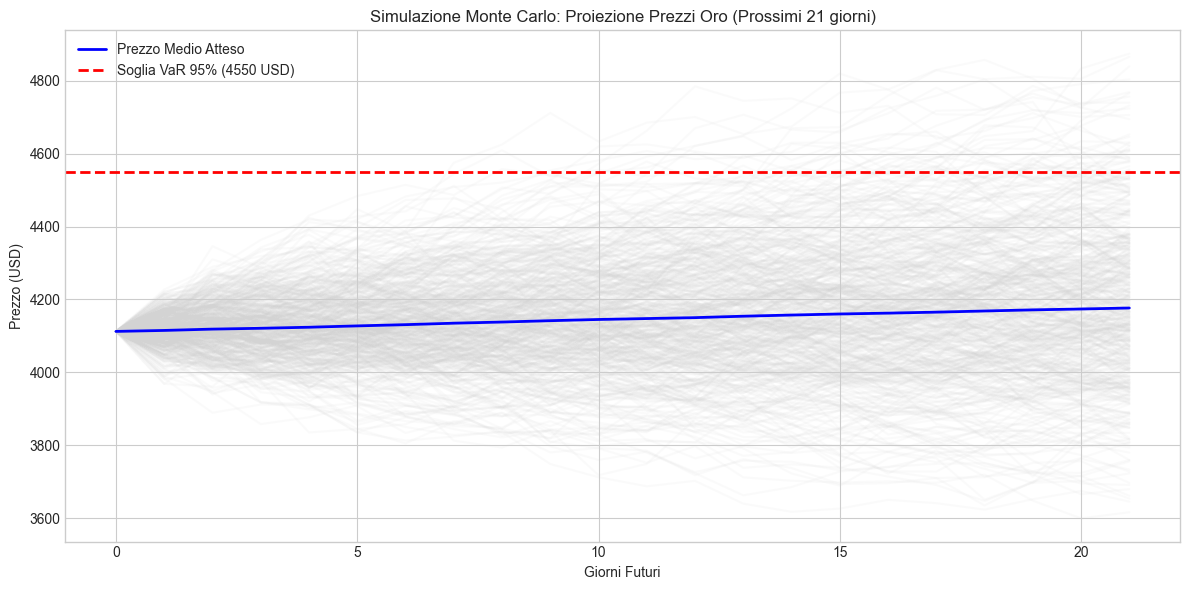

In [32]:
plt.figure(figsize=(12, 6))

# Disegniamo le prime 500 traiettorie in grigio semi-trasparente
plt.plot(traiettorie_oro[:, :500], color='lightgray', alpha=0.1)

# Aggiungiamo la traiettoria del Prezzo Medio (in blu)
plt.plot(np.mean(traiettorie_oro, axis=1), color='blue', linewidth=2, label='Prezzo Medio Atteso')

# CORREZIONE QUI: Usiamo il VaR in Dollari (var_95_prezzo_assoluto) e non la percentuale
plt.axhline(y=var_95_prezzo_assoluto, color='red', linestyle='--', linewidth=2, 
            label=f'Soglia VaR 95% ({var_95_prezzo_assoluto:.0f} USD)')

plt.title('Simulazione Monte Carlo: Proiezione Prezzi Oro (Prossimi 21 giorni)')
plt.xlabel('Giorni Futuri')
plt.ylabel('Prezzo (USD)')
plt.legend(loc='upper left') # Messo in alto a sinistra per non coprire le linee
plt.tight_layout()
plt.show()

In [33]:
# ==========================================
# ESECUZIONE DELLA SIMULAZIONE (Esempio Rame)
# ==========================================

# 1. Recuperiamo l'ultimo prezzo reale conosciuto dal nostro DataFrame iniziale
ultimo_prezzo_rame = prices_clean['Rame'].iloc[-1]

# 2. Avviamo la simulazione usando gli output della nostra funzione 'modella_e_prevedi'
traiettorie_rame = simulazione_monte_carlo_acquisti(
    prezzo_iniziale=ultimo_prezzo_rame, 
    media_prevista=media_rame, 
    volatilita_prevista=volatilita_rame
)

# ==========================================
# 3. CALCOLO DEL VaR CORRETTO
# ==========================================

prezzi_finali = traiettorie_rame[-1, :]
prezzo_medio_atteso = np.mean(prezzi_finali)

# A. VaR ASSOLUTO (IN DOLLARI) -> Questo va nel grafico!
# Calcola esattamente il prezzo al 95° percentile (es. 4450.50 USD)
var_95_prezzo_assoluto = np.percentile(prezzi_finali, 95) 

# B. VaR RELATIVO (IN PERCENTUALE) -> Questo è il tuo 7.45%
# Calcola di quanto si è alzato il prezzo rispetto all'inizio
var_95_percentuale = ((var_95_prezzo_assoluto - ultimo_prezzo_rame) / ultimo_prezzo_rame) * 100

print(f"\n--- RISULTATI BUSINESS (Orizzonte {len(media_rame)} giorni) ---")
print(f"Prezzo attuale del Rame: {ultimo_prezzo_rame:.2f} USD")
print(f"Prezzo medio atteso: {prezzo_medio_atteso:.2f} USD")
print(f"VaR 95% (Soglia Rischio in USD): {var_95_prezzo_assoluto:.2f} USD")
print(f"Rincaro massimo atteso (VaR in %): +{var_95_percentuale:.2f}%")

Avvio Simulazione Monte Carlo: 10000 scenari per 21 giorni...

--- RISULTATI BUSINESS (Orizzonte 21 giorni) ---
Prezzo attuale del Rame: 6.68 USD
Prezzo medio atteso: 6.69 USD
VaR 95% (Soglia Rischio in USD): 7.45 USD
Rincaro massimo atteso (VaR in %): +11.59%


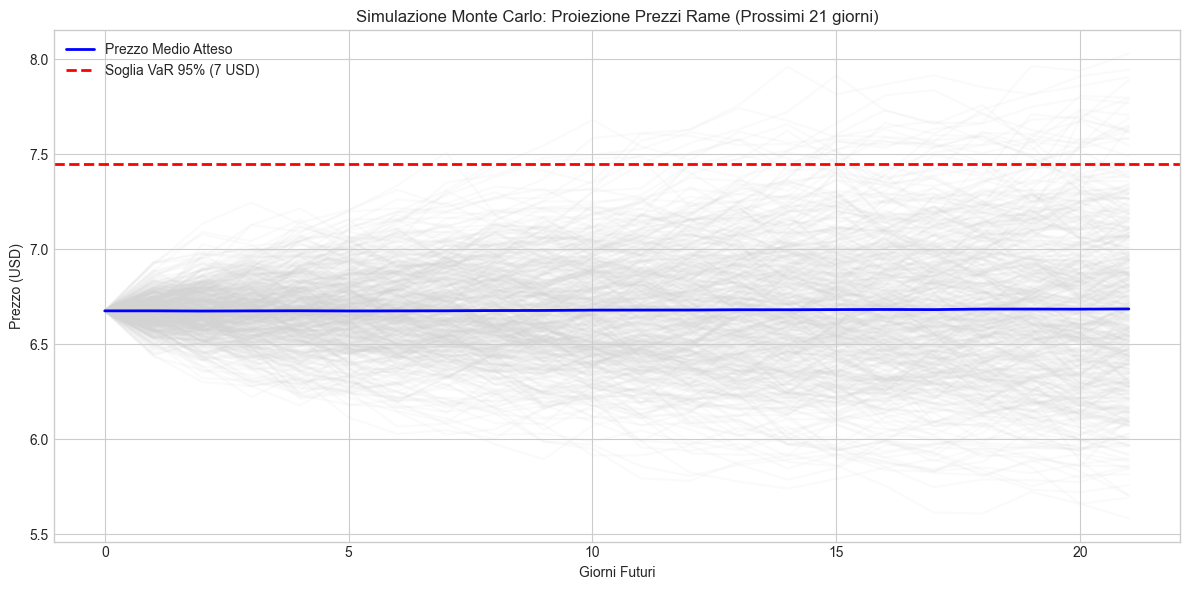

In [ ]:
plt.figure(figsize=(12, 6))

# Disegniamo le prime 500 traiettorie in grigio semi-trasparente
plt.plot(traiettorie_rame[:, :500], color='lightgray', alpha=0.1)

# Aggiungiamo la traiettoria del Prezzo Medio (in blu)
plt.plot(np.mean(traiettorie_rame, axis=1), color='blue', linewidth=2, label='Prezzo Medio Atteso')

# CORREZIONE QUI: Usiamo il VaR in Dollari (var_95_prezzo_assoluto) e non la percentuale
plt.axhline(y=var_95_prezzo_assoluto, color='red', linestyle='--', linewidth=2, 
            label=f'Soglia VaR 95% ({var_95_prezzo_assoluto:.0f} USD)')

plt.title('Simulazione Monte Carlo: Proiezione Prezzi Rame (Prossimi 21 giorni)')
plt.xlabel('Giorni Futuri')
plt.ylabel('Prezzo (USD)')
plt.legend(loc='upper left') # Messo in alto a sinistra per non coprire le linee
plt.tight_layout()
plt.show()

Immagina di dover chiudere il budget per il prossimo trimestre e debba comprare l'oro. Il prezzo attuale è di 2.000$ l'oncia e il mio modello ARIMA prevede che salirà leggermente a 2.020$.
Tuttavia, guardando la volatilità del mercato (GARCH) e lanciando la simulazione Monte Carlo, ho scoperto che c'è un 5% di probabilità (il VaR) che, a causa di uno shock di mercato, il prezzo superi i 2.150$ l'oncia entro un mese.
Se questo rincaro improvviso distrugge i margini di profitto, il mio consiglio per il dipartimento Supply Chain è quello di usare contratti Hedging (es. Options o Futures) oggi stesso, per bloccare il prezzo ed evitare che quel 5% di rischio diventi una perdita milionaria a bilancio.